Original Dataset Shape: (178, 14)
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065   

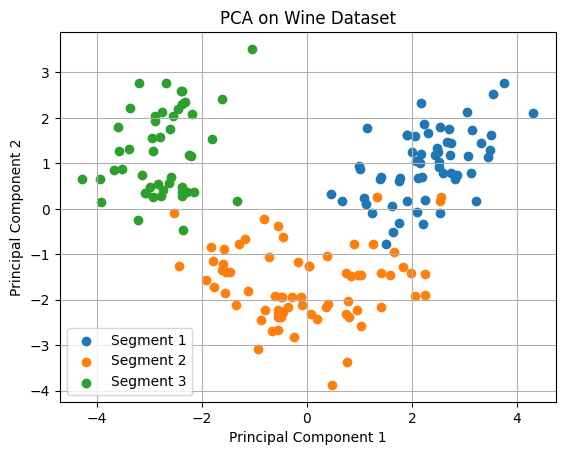

In [1]:

# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("Wine.csv")

print("Original Dataset Shape:", df.shape)
print(df.head())

# Separate features and target
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA: reduce 13 features to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame of principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Customer_Segment"] = y.values

print("\nTransformed Dataset:")
print(pca_df.head())

# Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Captured:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# Visualize the principal components
for segment in sorted(y.unique()):
    subset = pca_df[pca_df["Customer_Segment"] == segment]
    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=f"Segment {segment}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()

First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Actual Species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor']

Predicted Species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor']

Model Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
                 precision    recall  f1-score 

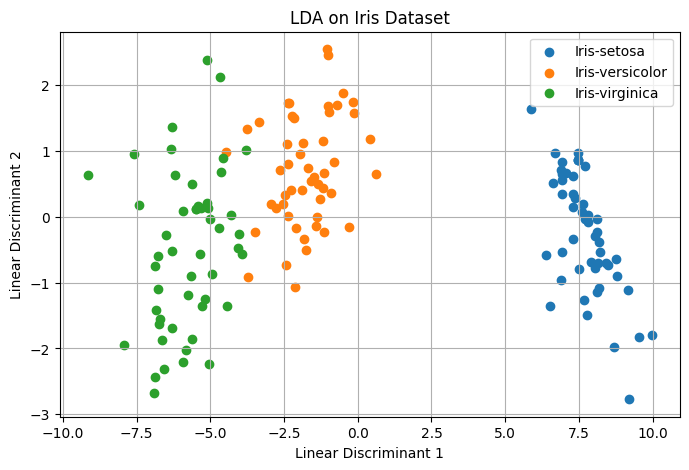


Predicted Species for New Flower: Iris-setosa


In [2]:

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load dataset
df = pd.read_csv("Iris.csv")

print("First five rows:")
print(df.head())

# Step 3: Separate features and target
X = df.drop(["Id", "Species"], axis=1)
y = df["Species"]

# Step 4: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Create and train LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

# Step 6: Predict flower species
y_pred = lda.predict(X_test)

print("\nActual Species:")
print(y_test.values[:10])

print("\nPredicted Species:")
print(y_pred[:10])

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 8: Display confusion matrix and report
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 9: Visualize LDA components
X_lda = lda.transform(X)

plt.figure(figsize=(8, 5))

for species in y.unique():
    mask = (y == species)
    plt.scatter(
        X_lda[mask, 0],
        X_lda[mask, 1],
        label=species
    )

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA on Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

# Step 10: Predict a new flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = lda.predict(new_flower)
print("\nPredicted Species for New Flower:", prediction[0])